# 🐱🚗 FarmTech Solutions — Ir Além 2 · Parte 1: Transfer Learning e Fine Tuning

**FIAP · Fase 6 · PBL — "Ir Além", Opção 2 (Transfer Learning, Fine Tuning e Segmentação)**

| Integrante | RM |
|---|---|
| Victor Vergara Koshikene | 568813 |
| Leonardo Lima de Queiroz | 573539 |
| Vinicius Prado Speria | 572741 |
| Leonardo Ribeiro de Souza | 571534 |
| Matheus Costa Manzoli Machado | 571814 |

---

## Contexto

Na Entrega 2, uma CNN treinada do zero classificou imagens de `gato` e `carro` do COCO com 7/8 acertos no
teste, mas com treino instável e um erro sugestivo: o gato siamês sobre um notebook (`000000425390.jpg`)
virou "carro". Este "Ir Além" testa duas abordagens para melhorar a classificação, em três notebooks:

| Notebook | Conteúdo |
|---|---|
| **01 — Transfer Learning** (este) | CNN do zero × EfficientNetB0 pré-treinada na ImageNet com fine tuning, em imagens originais (**H1**) |
| 02 — Segmentação | Rede de segmentação gera a máscara do objeto e apaga o fundo |
| 03 — Comparação final | Matriz 2×2 (CNN/TL × original/segmentada), ablações e conclusões (**H2**) |

## Hipótese H1

> Uma rede grande pré-treinada em um conjunto de dados imenso (ImageNet) classifica melhor que uma CNN
> treinada do zero com as nossas 64 imagens?

## Protocolo (fixado antes de olhar os testes)

- **Mesmos dados para os dois modelos:** 64 imagens de treino (32 gatos, 32 carros) e 8 de validação, os mesmos
  splits das Entregas 1 e 2. As imagens mistas (gato + carro) ficam fora, porque cada imagem precisa de um rótulo.
- **Dois testes:** o *teste original* (8 imagens, para comparar com a Entrega 2) e um **teste ampliado** de 52 imagens
  do COCO com os mesmos filtros (os 26 carros que sobram + 26 dos 70 gatos que sobram). O teste original já foi
  inspecionado na Entrega 2 e no planejamento; o ampliado não foi usado em nenhuma decisão, por isso é a base das
  conclusões. Cada erro no teste original vale 12,5 pontos percentuais; no ampliado, 1,9.
- **Mesma entrada, augmentation e cabeça** para os dois modelos; 5 sementes por modelo (média ± desvio padrão).
- Todas as escolhas (arquitetura, camada de congelamento, épocas, taxas de aprendizado) foram **fixadas a priori**
  em `src/config.py`, sem consultar os testes; a validação só escolhe o checkpoint (menor entropia cruzada). Ver a
  nota de processo no notebook 03, Seção 10.

## Sumário

1. Configuração do ambiente
2. Dados: splits das Entregas e teste ampliado
3. Pré-processamento
4. CNN do zero em Keras (port da Entrega 2)
5. Transfer Learning: EfficientNetB0 e camada de congelamento
6. Treino das 5 sementes
7. Resultados da H1
8. Conclusão da H1

> **Como executar:** abra no Colab com GPU (`Runtime → Change runtime type → T4 GPU`) e rode tudo. A célula de
> configuração monta o Drive (dados e pesos ficam em `MyDrive/FarmTech_Fase6/ir_alem`), clona o repositório e
> escolhe o backend do Keras. As saídas registradas aqui vêm da execução de referência (local, CPU, backend
> PyTorch) descrita no `ir_alem_opcao2/README.md`; no Colab os números podem variar levemente.

## 1. Configuração do ambiente

O enunciado pede uma rede "disponível no TensorFlow". Usamos a API **Keras 3** (`keras.applications`), que é
a API oficial de alto nível do TensorFlow e roda sobre três backends (TensorFlow, PyTorch ou JAX) sem mudar o
código. Isso resolve um problema prático: no runtime atual do Colab (out/2026, CUDA 13) o TensorFlow
pré-instalado registra `Could not find cuda drivers ... GPU will not be used` (visto na Entrega 1), enquanto o
PyTorch usa a T4 normalmente. A célula abaixo usa o backend TensorFlow se ele enxergar uma GPU (ex.: runtime
fixo `2026.07`); caso contrário, o backend PyTorch (GPU no Colab, CPU na execução local). O backend e o
dispositivo usados ficam registrados na saída.

In [1]:
# ---------------- Configuração do ambiente ----------------
import os, shutil, subprocess, sys
from pathlib import Path

NO_COLAB = "google.colab" in sys.modules
URL_REPO = "https://github.com/koshivv/fiap-farmtech_solutions-fase06.git"

if NO_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                              # dados e pesos persistem entre sessões
    REPO_DIR = Path("/content/fiap-farmtech_solutions-fase06")
    if (REPO_DIR / "ir_alem_opcao2").exists():                 # sessão já tinha o clone: traz correções
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q", "--ff-only"], check=False)
    else:                                                      # main após o merge do PR; antes, o ramo do Ir Além
        shutil.rmtree(REPO_DIR, ignore_errors=True)
        for ramo in (os.environ.get("FARMTECH_RAMO", "main"), "ir-alem-opcao2"):
            subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", ramo, URL_REPO, str(REPO_DIR)], check=False)
            if (REPO_DIR / "ir_alem_opcao2").exists():
                break
            shutil.rmtree(REPO_DIR, ignore_errors=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
else:                                                          # local: sobe até achar a raiz do repositório
    REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ir_alem_opcao2" / "src").is_dir())

sys.path.insert(0, str(REPO_DIR / "ir_alem_opcao2"))
from src import ambiente
BACKEND = ambiente.preparar_backend()                          # precisa vir ANTES do import do keras

import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config, dados, metricas, modelos, treino, visualizacao as vis

config.garantir_pastas()
vis.aplicar_estilo()
AMBIENTE = ambiente.descrever_ambiente()
AMBIENTE["dispositivo_keras"] = ambiente.dispositivo_keras()
for chave, valor in AMBIENTE.items():
    print(f"{chave:18s}: {valor}")
print("Dados em:", config.DADOS_DIR)

python            : 3.11.9
colab             : False
keras_backend     : torch
commit            : f946c6e
keras             : 3.13.2
torch             : 2.14.1
jax               : 0.10.2
ultralytics       : 8.4.175
numpy             : 2.4.6
pandas            : 3.0.6
scikit-learn      : 1.9.1
gpu_torch         : False
dispositivo_keras : CPU
Dados em: C:\Users\leonardo.souza\Workspace\FarmTech - Fase 6\fiap-farmtech_solutions-fase06\ir_alem_opcao2\_dados


## 2. Dados: splits das Entregas e teste ampliado

### 2.1 Reprodutibilidade do manifesto

As imagens não estão no repositório: o `dataset/manifesto_dataset.csv` diz quais são. Antes de usá-lo,
refazemos a seleção da Entrega 1 (mesmos filtros e semente 42) a partir das anotações oficiais do COCO e
conferimos que o resultado é idêntico ao manifesto versionado.

In [2]:
# ---------------- Anotações COCO e manifesto ----------------
coco = dados.carregar_coco()                                   # baixa o JSON do val2017 só na 1ª vez
manifesto = dados.ler_manifesto()
assert dados.reproduzir_manifesto(coco).equals(manifesto), "A seleção não reproduziu o manifesto."
print("✅ Seleção da Entrega 1 reproduzida exatamente:", len(manifesto), "imagens")

loading annotations into memory...


Done (t=0.79s)
creating index...
index created!
✅ Seleção da Entrega 1 reproduzida exatamente: 85 imagens


### 2.2 Teste ampliado

O teste original tem só 8 imagens de classe única. Com os **mesmos filtros** da Entrega 1 sobram, no
val2017, 70 gatos e 26 carros que não foram usados. Sorteamos 26 de cada (semente 42) para um teste
balanceado de 52 imagens. O rótulo vem do próprio COCO, sem rotulação manual, e as imagens não foram
usadas em nenhuma decisão. A lista fica versionada em `ir_alem_opcao2/dados/manifesto_teste_ampliado.csv`.

In [3]:
# ---------------- Sorteio do teste ampliado ----------------
ampliado = dados.selecionar_teste_ampliado(coco, manifesto)
if config.MANIFESTO_AMPLIADO.exists():                         # versão do repositório deve bater com o sorteio
    assert pd.read_csv(config.MANIFESTO_AMPLIADO).equals(ampliado), "Teste ampliado diferente do versionado."
else:
    config.MANIFESTO_AMPLIADO.parent.mkdir(parents=True, exist_ok=True)
    ampliado.to_csv(config.MANIFESTO_AMPLIADO, index=False)
print(ampliado.grupo.value_counts().to_dict())

{'gato': 26, 'carro': 26}


In [4]:
# ---------------- Download das imagens e checagem de quase-duplicatas ----------------
todas = pd.concat([manifesto, ampliado], ignore_index=True)
falhas = dados.baixar_imagens(todas)                           # só baixa o que ainda não existe
assert not falhas, f"Falha no download: {falhas}"

# Nenhuma imagem nova pode ser cópia (ou quase cópia) de uma das 85 usadas nas Entregas
dist, img_a, img_b = dados.menor_distancia_hash([config.IMAGENS_DIR / a for a in ampliado.arquivo],
                                                [config.IMAGENS_DIR / a for a in manifesto.arquivo])
print(f"Menor distância dHash (64 bits) entre teste ampliado e as 85 imagens: {dist} ({img_a} × {img_b})")
assert dist > 8, "Possível quase-duplicata entre o teste ampliado e as imagens das Entregas."

Menor distância dHash (64 bits) entre teste ampliado e as 85 imagens: 15 (000000054593.jpg × 000000078426.jpg)


### 2.3 Tabela das imagens e um atalho a vigiar

A tabela abaixo junta, para cada imagem, o conjunto, a licença (32 das 85 originais proíbem obras derivadas, o
que importa para publicar recortes) e se há uma **pessoa** na cena. Em cerca de 2/3 das fotos de carro há pessoas
(cenas de rua); nas de gato, em menos de 10%. Um classificador pode acertar "carro" olhando a pessoa, e não o carro.
Esse atalho de contexto é uma das razões para testar a pré-segmentação (H2) e para reportarmos resultados por estrato.

In [5]:
# ---------------- Tabela das imagens ----------------
tabela = dados.tabela_imagens(coco, manifesto, ampliado)
tabela.to_csv(config.RESULTADOS_DIR / "imagens.csv", index=False)
display(pd.crosstab(tabela.conjunto, tabela.grupo, margins=True, margins_name="total"))

unica = tabela[tabela.grupo != "mista"]                         # classificação: só imagens de classe única
pessoa = unica.groupby(["conjunto", "grupo"]).tem_pessoa.agg(["sum", "count"])
pessoa["% com pessoa"] = (100 * pessoa["sum"] / pessoa["count"]).round(0)
display(pessoa.rename(columns={"sum": "com pessoa", "count": "imagens"}))

grupo,carro,gato,mista,total
conjunto,,,,
teste_ampliado,26,26,0,52
teste_original,4,4,1,9
treino,32,32,3,67
validacao,4,4,1,9
total,66,66,5,137


com pessoa  imagens  % com pessoa
conjunto       grupo                                   
teste_ampliado carro          18       26          69.0
               gato            2       26           8.0
teste_original carro           4        4         100.0
               gato            0        4           0.0
treino         carro          17       32          53.0
               gato            1       32           3.0
validacao      carro           4        4         100.0
               gato            2        4          50.0

## 3. Pré-processamento

| Etapa | Escolha | Por quê |
|---|---|---|
| Tamanho | 224×224 para **os dois** modelos | É a resolução em que a EfficientNetB0 foi treinada. Usar a mesma entrada na CNN do zero elimina a resolução como diferença entre os modelos (a Entrega 2 usava 128 px; a CNN tem *global average pooling* e aceita qualquer tamanho sem mudar o número de parâmetros). |
| Redimensionamento | Sem preservar a proporção (bilinear) | Igual ao `Resize` da Entrega 2. As imagens têm proporção largura/altura de 0,66 a 2,96; recortar o centro poderia cortar o objeto. |
| Normalização da EfficientNetB0 | **Nenhuma externa**: pixels crus em [0, 255] | A `keras.applications.EfficientNetB0` já traz `Rescaling` + `Normalization` com média/desvio da ImageNet dentro do modelo; o `preprocess_input` dela é identidade. Normalizar fora aplicaria a transformação duas vezes. |
| Normalização da CNN | `Rescaling(1/127.5, -1)` → [-1, 1] | Equivale ao `Normalize(0,5; 0,5)` da Entrega 2. |
| Augmentation (só no treino) | RandomResizedCrop (área 0,6–1) → espelhamento → rotação ±10° → brilho/contraste/saturação ±30% em ordem aleatória | A **mesma** sequência da Entrega 2, nos dois modelos. Implementada em `src/aumento.py` com as mesmas operações PIL que o torchvision usa em imagens PIL, sobre a imagem em resolução original. O Keras 3.13 não tem RandomResizedCrop e seus padrões de contraste, saturação e brilho divergem do torchvision; uma versão inicial com camadas Keras também foi bem mais lenta em CPU. |

In [6]:
# ---------------- Matrizes de entrada (condição O = imagem original) ----------------
TAB = {c: unica[unica.conjunto == c].reset_index(drop=True) for c in dados.CONJUNTOS}
X_O = dados.carregar_condicao(TAB, "O")                        # avaliação: só redimensiona para 224x224
TREINO_O = dados.imagens_treino(TAB["treino"], "O")            # treino: resolução original (augmentation)
for c in dados.CONJUNTOS:
    print(f"{c:15s} -> {X_O[c].shape} | gatos: {(TAB[c].y == 0).sum()} | carros: {(TAB[c].y == 1).sum()}")

treino          -> (64, 224, 224, 3) | gatos: 32 | carros: 32
validacao       -> (8, 224, 224, 3) | gatos: 4 | carros: 4
teste_original  -> (8, 224, 224, 3) | gatos: 4 | carros: 4
teste_ampliado  -> (52, 224, 224, 3) | gatos: 26 | carros: 26


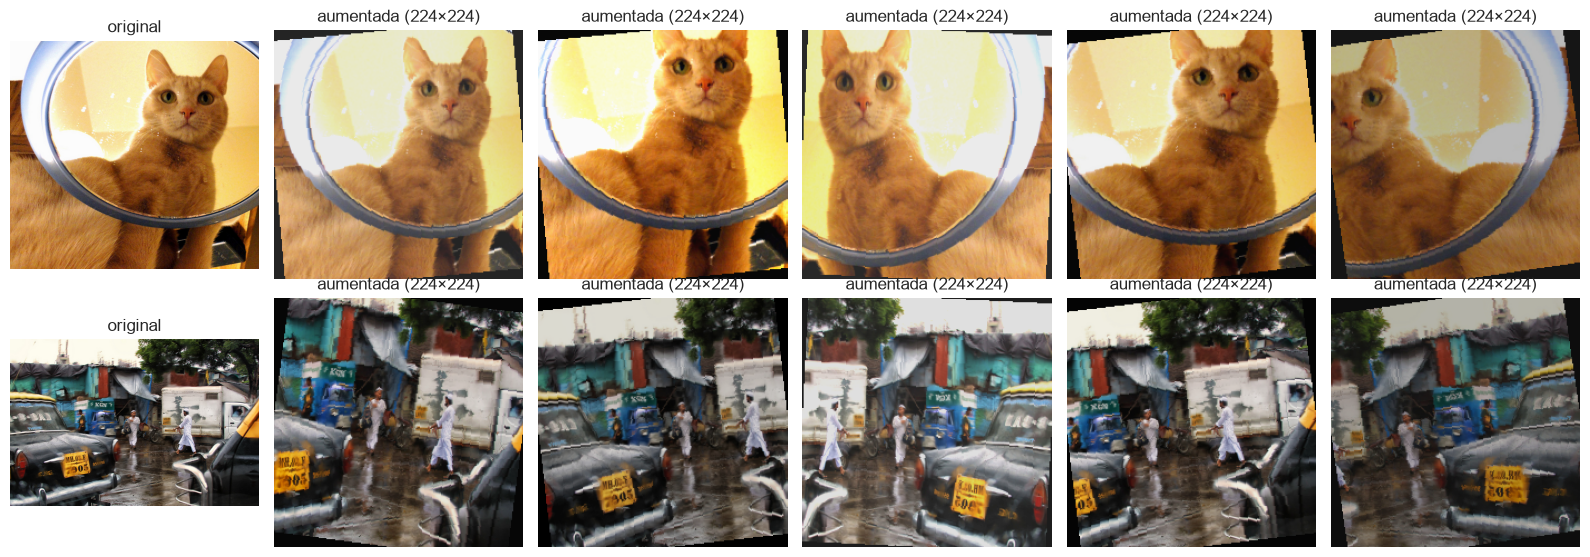

In [7]:
# ---------------- Exemplos da augmentation (o que a rede vê no treino) ----------------
from src import aumento
fig, eixos = plt.subplots(2, 6, figsize=(16, 5.6))
permitidas = TAB["treino"][TAB["treino"].permite_derivados]    # licença permite publicar versões alteradas
exemplos = [permitidas[permitidas.grupo == g].index[0] for g in config.CLASSES]   # um gato e um carro
for linha, indice in zip(eixos, exemplos):
    linha[0].imshow(TREINO_O[indice])
    linha[0].set_title("original")
    for k, ax in enumerate(linha[1:]):
        ax.imshow(aumento.aumentar(TREINO_O[indice], np.random.default_rng([config.SEED, k])))
        ax.set_title("aumentada (224×224)")
    for ax in linha:
        ax.axis("off")
fig.tight_layout()
plt.show()

## 4. CNN do zero em Keras (port da Entrega 2)

Os pesos da CNN da Entrega 2 ficaram só no Drive de quem a executou e ela foi escrita em PyTorch. Para comparar
os dois classificadores **no mesmo framework, com o mesmo pipeline de dados**, a CNN foi portada para Keras com
a mesma arquitetura:

| Etapa | Camadas | Saída (224 px) |
|---|---|---|
| Blocos 1–4 | Conv 3×3 (32 / 64 / 128 / 128) + BatchNorm + ReLU + MaxPool | 128 × 14 × 14 |
| Cabeça | GlobalAveragePooling + Dropout (0,3) + Dense(2) | 2 classes |

Ajustes para que o port se comporte como o original (os padrões do Keras são outros):

| Item | PyTorch (Entrega 2) | Keras (aqui) |
|---|---|---|
| Inicialização | `kaiming_uniform(a=√5)` | `VarianceScaling(1/3, fan_in, uniforme)` (mesma distribuição) |
| BatchNorm | momentum 0,1, eps 1e-5 | `momentum=0.9`, `epsilon=1e-5` (convenções inversas) |
| Weight decay | `Adam(weight_decay=1e-4)`: L2 acoplado ao gradiente | Regularizador L2 de 5e-5 em todos os pesos (gradiente 2·5e-5·θ = 1e-4·θ) |
| Adam | eps 1e-8 | `epsilon=1e-8` |
| Checkpoint | menor perda de validação em 100 épocas | idem (entropia cruzada, sem o termo L2) |

A contagem de parâmetros treináveis tem de bater com os **241.794** da Entrega 2. O Keras mostra 704 parâmetros
"congelados" a mais: são as médias e variâncias móveis das BatchNorm, que o PyTorch guarda como *buffers*.

In [8]:
# ---------------- Conferência do port ----------------
cnn = modelos.criar_cnn_do_zero(seed=config.SEED)
parametros = modelos.contar_parametros(cnn)
print(parametros)
assert parametros["treinaveis"] == 241_794, "O port não tem a mesma arquitetura da Entrega 2."
print("✅ Mesma arquitetura da Entrega 2 (241.794 parâmetros treináveis).")

{'treinaveis': 241794, 'congelados': 704}
✅ Mesma arquitetura da Entrega 2 (241.794 parâmetros treináveis).


## 5. Transfer Learning: EfficientNetB0

### 5.1 Por que a EfficientNetB0

| Rede (`keras.applications`) | Parâmetros | Top-1 ImageNet | Pré-processamento | Comentário para 64 imagens |
|---|---|---|---|---|
| **EfficientNetB0** | 5,3 M | 77,1% | embutido no modelo | maior top-1 entre as redes de até ~5 M de parâmetros; pipeline idêntico para imagens originais e segmentadas |
| MobileNetV2 | 3,5 M | 71,3% | `preprocess_input` → [-1, 1] | alternativa mais leve; 6 p.p. abaixo na ImageNet |
| InceptionV3 | 23,9 M | 77,9% | `preprocess_input` → [-1, 1] | +0,8 p.p. com 4,5× mais parâmetros e entrada nativa de 299 px |
| ResNet50 | 25,6 M | 74,9% | `caffe` (BGR − média) | 15 M de parâmetros só no último estágio: excesso para 64 imagens |
| VGG16 | 138 M | 71,3% | `caffe` | 7 M de parâmetros só no `block5`; 15 GFLOPs por imagem |

Fontes: tabela oficial de `keras.io/api/applications` e código-fonte do Keras 3.13.

**Ponto de partida (efeito teto).** A ImageNet tem 5 classes de gato doméstico (inclusive "Siamese cat") e cerca
de 15 de carros e partes de carro. A célula abaixo usa a EfficientNetB0 original, **sem nenhum treino**, e
classifica cada imagem de treino+validação somando as probabilidades das classes de gato contra as de carro.
Se ela já acertar quase tudo, a acurácia do TL tende a 100% e as diferenças terão de aparecer nas métricas de
probabilidade (log-loss, Brier) e no teste ampliado. Os testes não são usados aqui.

In [9]:
# ---------------- Zero-shot ImageNet (treino + validação) ----------------
GATOS_IMAGENET = [281, 282, 283, 284, 285]                     # tabby, tiger cat, Persian, Siamese, Egyptian
CARROS_IMAGENET = [407, 436, 468, 479, 511, 581, 609, 627, 656, 661, 675, 717, 734, 751, 817, 864]
imagenet = keras.applications.EfficientNetB0(weights="imagenet")   # com a cabeça de 1.000 classes
linhas = []
for conjunto in ("treino", "validacao"):
    probs = imagenet.predict(X_O[conjunto], verbose=0)
    p_gato, p_carro = probs[:, GATOS_IMAGENET].sum(1), probs[:, CARROS_IMAGENET].sum(1)
    pred = (p_carro > p_gato).astype(int)
    linhas.append({"conjunto": conjunto, "acertos": f"{(pred == TAB[conjunto].y).sum()}/{len(pred)}",
                   "P média do conjunto certo": round(float(np.where(TAB[conjunto].y == 1, p_carro, p_gato).mean()), 3)})
display(pd.DataFrame(linhas).set_index("conjunto"))
del imagenet
keras.backend.clear_session()

,acertos,P média do conjunto certo
conjunto,,
treino,64/64,0.203
validacao,8/8,0.075



### 5.2 Fine tuning em duas fases e camada de congelamento

1. **Fase 1 — feature extraction (30 épocas, Adam 1e-3):** base congelada, só a cabeça treina (2.562 parâmetros).
   Treinar a cabeça primeiro evita que gradientes grandes de uma cabeça aleatória destruam os pesos pré-treinados.
2. **Fase 2 — fine tuning (30 épocas, Adam 1e-5):** liberamos o treino de `block7a_expand_conv` até o fim da base,
   ou seja, **N = 16 camadas** (o último bloco MBConv e a convolução de topo), recompilando o modelo. Dessas 16, 6 têm
   pesos treináveis (convoluções e *squeeze-and-excitation*), 4 são BatchNormalization que continuam congeladas e 6
   não têm pesos (ativações, reshape, multiplicação).

Por que esse corte:

- os blocos iniciais extraem bordas e texturas genéricas, úteis para qualquer imagem; o último bloco é o mais
  específico das 1.000 classes da ImageNet e, por hipótese, o que mais se beneficia de se adaptar a "gato × carro";
- **orçamento de dados**: são ~1,1 M de parâmetros liberados (~17,5 mil por imagem de treino). Liberar a partir do
  `block6a` daria 3,1 M (77% da base); só a `top_conv` (0,4 M) ficaria perto de não fazer fine tuning;
- o corte respeita a fronteira de um bloco: o exemplo oficial do Keras alerta que cortar um bloco ao meio piora o
  resultado (o padrão do exemplo, as últimas 20 camadas da base, começaria no meio do `block6d`; o próprio exemplo
  sugere cortar pelo nome, como `"block7"`, que é o nosso corte);
- as **BatchNormalization continuam congeladas**: com lotes de 16 imagens, as estatísticas móveis seriam
  reestimadas com ruído e apagariam o que a rede aprendeu na ImageNet;
- o *stochastic depth* da EfficientNet (Dropout dentro dos blocos) é **desligado**: assim a fase 1 é feature
  extraction de fato (a base produz as mesmas features no treino e na inferência). No Keras 3 não basta chamar a
  base com `training=False`, porque o `fit` sobrescreve esse argumento nas camadas internas;
- o corte é feito pelo **nome** da camada, porque o índice muda com os pesos (237 camadas sem pesos, 238 com
  `weights="imagenet"`).

A tabela abaixo é calculada a partir do próprio modelo.

In [10]:
# ---------------- Pontos de corte possíveis na EfficientNetB0 ----------------
import math
modelo_tl, base = modelos.criar_modelo_tl(seed=config.SEED)
nomes = [camada.name for camada in base.layers]
total_base = base.count_params()
linhas = []
for rotulo, nome in [("só top_conv", "top_conv"), ("block7a + top  ← escolhido", "block7a_expand_conv"),
                     ("block6a em diante", "block6a_expand_conv"), ("block5a em diante", "block5a_expand_conv")]:
    inicio = nomes.index(nome)
    liberadas = base.layers[inicio:]
    bn = [c for c in liberadas if isinstance(c, keras.layers.BatchNormalization)]
    treinaveis = sum(math.prod(w.shape) for c in liberadas if c not in bn for w in c.weights)
    linhas.append({"corte": rotulo, "1ª camada liberada": nome, "índice": inicio, "camadas liberadas": len(liberadas),
                   "BN mantidas congeladas": len(bn), "parâmetros treináveis": treinaveis,
                   "% da base": round(100 * treinaveis / total_base, 1),
                   "parâmetros por imagem de treino": round(treinaveis / len(TAB["treino"]))})
print(f"Base: {len(base.layers)} camadas, {total_base:,} parâmetros")
display(pd.DataFrame(linhas).set_index("corte"))

modelos.descongelar_topo(base)                                 # conferência do corte escolhido
print("Treináveis após descongelar (base + cabeça):", modelos.contar_parametros(modelo_tl))

Base: 238 camadas, 4,049,571 parâmetros


,1ª camada liberada,índice,camadas liberadas,BN mantidas congeladas,parâmetros treináveis,% da base,parâmetros por imagem de treino
corte,,,,,,,
só top_conv,top_conv,235,3,1,409600,10.1,6400
block7a + top ← escolhido,block7a_expand_conv,222,16,4,1121584,27.7,17525
block6a em diante,block6a_expand_conv,163,75,16,3129884,77.3,48904
block5a em diante,block5a_expand_conv,120,118,25,3665064,90.5,57267


Treináveis após descongelar (base + cabeça): {'treinaveis': 1124146, 'congelados': 2927987}


## 6. Treino das 5 sementes

Para cada semente treinamos a CNN do zero e a EfficientNetB0 com os mesmos dados. As previsões são salvas
imagem a imagem (validação, teste original e teste ampliado), junto com o histórico e os pesos. Execuções já
concluídas são lidas do disco/Drive, o que permite retomar o notebook depois de uma queda de sessão.
A EfficientNetB0 também é avaliada **ao fim da fase 1**, para medir o que o fine tuning acrescenta.

In [11]:
# ---------------- Treino (condição O: imagens originais) ----------------
import time
inicio = time.perf_counter()
execucoes = []
for seed in config.SEEDS:
    for tipo in ("cnn", "tl"):
        r = treino.executar(tipo, "O", seed, TREINO_O, X_O, TAB)
        execucoes.append(r)
        print(f"{tipo:3s} seed {seed}: melhor época {int(r['execucao'].melhor_epoca[0]):3d} | "
              f"treino {float(r['execucao'].tempo_treino_s[0]):6.1f} s")
print(f"⏱️  Tempo total desta célula: {time.perf_counter() - inicio:.0f} s")

predicoes = pd.concat([r["predicoes"] for r in execucoes], ignore_index=True)
historicos = pd.concat([r["historico"] for r in execucoes], ignore_index=True)
resumo_exec = pd.concat([r["execucao"] for r in execucoes], ignore_index=True)
predicoes.to_csv(config.RESULTADOS_DIR / "predicoes_O.csv", index=False)
historicos.to_csv(config.RESULTADOS_DIR / "historicos_O.csv", index=False)
resumo_exec.to_csv(config.RESULTADOS_DIR / "execucoes_O.csv", index=False)
display(resumo_exec.groupby("modelo")[["melhor_epoca", "tempo_treino_s", "parametros_treinaveis"]].agg(["mean", "std"]).round(1))

cnn seed 42: melhor época  30 | treino  540.3 s


tl  seed 42: melhor época  60 | treino  273.9 s


cnn seed 43: melhor época  17 | treino 1105.9 s


tl  seed 43: melhor época  60 | treino  610.5 s


cnn seed 44: melhor época  17 | treino  881.8 s


...

cnn seed 45: melhor época  17 | treino 1022.6 s


tl  seed 45: melhor época  52 | treino  603.8 s


cnn seed 46: melhor época  34 | treino 1164.6 s


tl  seed 46: melhor época  60 | treino  596.7 s
⏱️  Tempo total desta célula: 7467 s


melhor_epoca      tempo_treino_s        parametros_treinaveis     
               mean  std           mean    std                  mean  std
modelo                                                                   
cnn            23.0  8.3          943.0  248.9              241794.0  0.0
tl             58.2  3.5          532.0  144.9             1124146.0  0.0

## 7. Resultados da H1

### 7.1 Métricas gerais (média ± desvio padrão em 5 sementes)

- **acurácia** e **F1 macro**: acertos de classe;
- **log-loss** e **Brier** (↓ melhor) e **P(classe correta)** (↑ melhor): medem a *confiança* do acerto, o que
  distingue modelos mesmo quando a acurácia satura em 100%.

In [12]:
# ---------------- Tabela principal ----------------
finais = predicoes[predicoes.fase == "final"]
por_semente = metricas.metricas_por_semente(finais, ["conjunto", "modelo"])
por_semente.to_csv(config.RESULTADOS_DIR / "metricas_por_semente_O.csv", index=False)
COLUNAS = ["acuracia", "f1_macro", "log_loss", "brier", "p_correta"]
tabela_h1 = metricas.media_desvio(por_semente, ["conjunto", "modelo"], COLUNAS)
display(tabela_h1.loc[["teste_ampliado", "teste_original", "validacao"]])

acuracia       f1_macro       log_loss  \
conjunto       modelo                                                
teste_ampliado cnn     0.785 ± 0.053  0.782 ± 0.058  0.608 ± 0.101   
               tl      0.988 ± 0.011  0.988 ± 0.011  0.039 ± 0.005   
teste_original cnn       0.9 ± 0.056  0.898 ± 0.057  0.209 ± 0.056   
               tl          1.0 ± 0.0      1.0 ± 0.0  0.003 ± 0.001   
validacao      cnn      0.75 ± 0.088   0.748 ± 0.09  0.422 ± 0.088   
               tl        0.9 ± 0.056  0.898 ± 0.057   0.18 ± 0.018   

                               brier      p_correta  
conjunto       modelo                                
teste_ampliado cnn     0.165 ± 0.029  0.714 ± 0.044  
               tl      0.008 ± 0.002  0.966 ± 0.004  
teste_original cnn     0.065 ± 0.023  0.849 ± 0.029  
               tl          0.0 ± 0.0  0.997 ± 0.001  
validacao      cnn     0.144 ± 0.036  0.706 ± 0.046  
               tl       0.06 ± 0.009   0.87 ± 0.008

In [13]:
# ---------------- Precisão, recall e F1 por classe (teste ampliado) ----------------
COLUNAS_CLASSE = [f"{m}_{c}" for c in config.CLASSES for m in ("precisao", "recall", "f1")]
display(metricas.media_desvio(por_semente[por_semente.conjunto == "teste_ampliado"], ["modelo"], COLUNAS_CLASSE))

,precisao_gato,recall_gato,f1_gato,precisao_carro,recall_carro,f1_carro
modelo,,,,,,
cnn,0.82 ± 0.033,0.731 ± 0.133,0.767 ± 0.084,0.766 ± 0.074,0.838 ± 0.05,0.797 ± 0.035
tl,1.0 ± 0.0,0.977 ± 0.021,0.988 ± 0.011,0.978 ± 0.02,1.0 ± 0.0,0.989 ± 0.01


### 7.2 Matrizes de confusão e curvas de treino

As matrizes somam as previsões das 5 sementes (52 imagens × 5 = 260 previsões por modelo no teste ampliado).

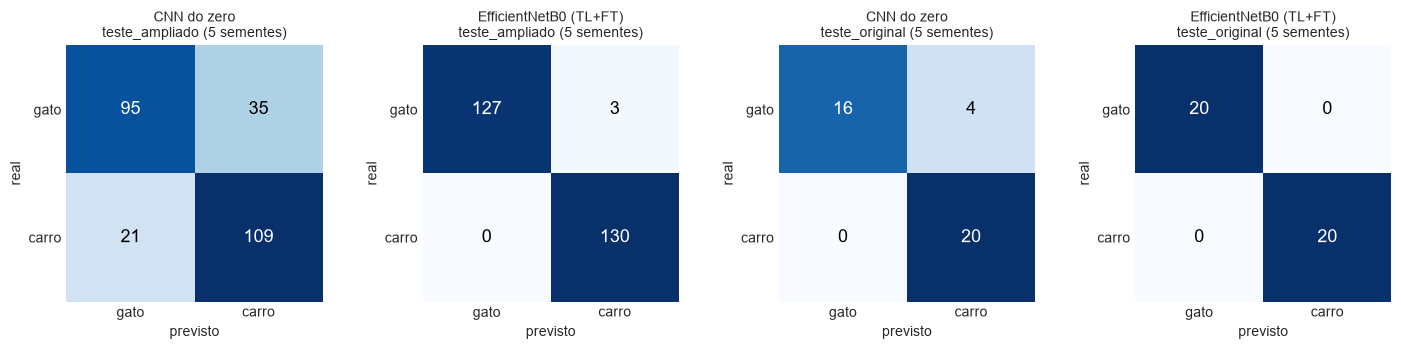

In [14]:
# ---------------- Matrizes de confusão (soma das 5 sementes) ----------------
paineis = []
for conjunto in ("teste_ampliado", "teste_original"):
    for tipo, nome in (("cnn", "CNN do zero"), ("tl", "EfficientNetB0 (TL+FT)")):
        sel = finais[(finais.conjunto == conjunto) & (finais.modelo == tipo)]
        paineis.append((f"{nome}\n{conjunto} (5 sementes)", metricas.matriz_confusao(sel)))
fig = vis.matrizes_confusao(paineis)
vis.salvar(fig, "h1_matrizes_confusao.png")
plt.show()

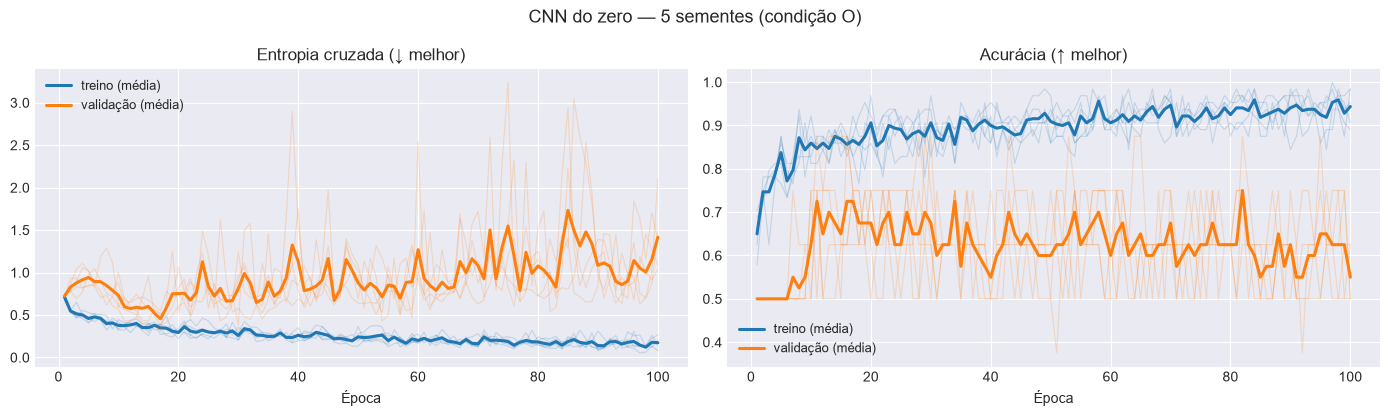

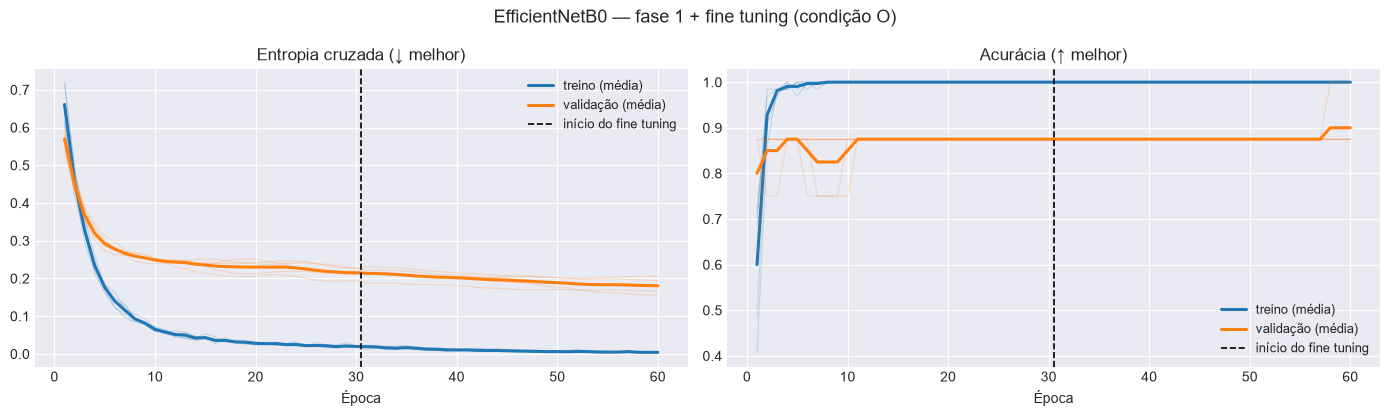

In [15]:
# ---------------- Curvas de treino x validação ----------------
fig = vis.curvas_treino(historicos[historicos.modelo == "cnn"], "CNN do zero — 5 sementes (condição O)")
vis.salvar(fig, "h1_curvas_cnn.png")
plt.show()
fig = vis.curvas_treino(historicos[historicos.modelo == "tl"], "EfficientNetB0 — fase 1 + fine tuning (condição O)",
                        inicio_fase2=config.EPOCAS_TL_FASE1)
vis.salvar(fig, "h1_curvas_tl.png")
plt.show()

### 7.3 O fine tuning acrescentou algo?

Comparação da mesma EfficientNetB0 ao fim da fase 1 (só a cabeça treinada) e ao fim da fase 2 (fine tuning).

In [16]:
# ---------------- Feature extraction x fine tuning ----------------
tl = predicoes[predicoes.modelo == "tl"]
por_fase = metricas.metricas_por_semente(tl, ["conjunto", "fase"])
display(metricas.media_desvio(por_fase, ["conjunto", "fase"], COLUNAS).loc[["teste_ampliado", "validacao"]])
print("Parâmetros treináveis — fase 1:", int(resumo_exec[resumo_exec.modelo == "tl"].parametros_treinaveis_fase1.iloc[0]),
      "| fase 2:", int(resumo_exec[resumo_exec.modelo == "tl"].parametros_treinaveis.iloc[0]))

acuracia       f1_macro       log_loss  \
conjunto       fase                                                 
teste_ampliado final  0.988 ± 0.011  0.988 ± 0.011  0.039 ± 0.005   
               fase1    0.981 ± 0.0    0.981 ± 0.0  0.076 ± 0.009   
validacao      final    0.9 ± 0.056  0.898 ± 0.057   0.18 ± 0.018   
               fase1    0.875 ± 0.0    0.873 ± 0.0  0.214 ± 0.014   

                              brier      p_correta  
conjunto       fase                                 
teste_ampliado final  0.008 ± 0.002  0.966 ± 0.004  
               fase1  0.016 ± 0.003  0.936 ± 0.008  
validacao      final   0.06 ± 0.009   0.87 ± 0.008  
               fase1  0.073 ± 0.007  0.847 ± 0.007

Parâmetros treináveis — fase 1: 2562 | fase 2: 1124146


### 7.4 Teste estatístico pareado

Para comparar os modelos nas **mesmas imagens**, usamos o consenso das 5 sementes (média das probabilidades) e o
**teste de McNemar exato**, que olha só as imagens em que os modelos discordam. O intervalo de confiança de 95% da
acurácia vem de *bootstrap* sobre as imagens.

In [17]:
# ---------------- McNemar e intervalos de confiança ----------------
consenso = metricas.predicao_consenso(finais, ["conjunto", "modelo"])
linhas = []
for conjunto in ("teste_ampliado", "teste_original"):
    sel = consenso[consenso.conjunto == conjunto]
    cnn_c = sel[sel.modelo == "cnn"].set_index("arquivo").correto
    tl_c = sel[sel.modelo == "tl"].set_index("arquivo").correto.loc[cnn_c.index]
    teste = metricas.mcnemar_exato(tl_c, cnn_c)
    linhas.append({"conjunto": conjunto, "imagens": len(cnn_c),
                   "acurácia CNN (consenso)": round(cnn_c.mean(), 3), "IC95% CNN": metricas.ic_bootstrap(cnn_c),
                   "acurácia TL (consenso)": round(tl_c.mean(), 3), "IC95% TL": metricas.ic_bootstrap(tl_c),
                   "só TL acerta": teste["so_A_acerta"], "só CNN acerta": teste["so_B_acerta"],
                   "p-valor McNemar": round(teste["p_valor"], 4)})
display(pd.DataFrame(linhas).set_index("conjunto"))

,imagens,acurácia CNN (consenso),IC95% CNN,acurácia TL (consenso),IC95% TL,só TL acerta,só CNN acerta,p-valor McNemar
conjunto,,,,,,,,
teste_ampliado,52,0.808,"(0.692, 0.904)",1.0,"(1.0, 1.0)",10,0,0.002
teste_original,8,0.875,"(0.625, 1.0)",1.0,"(1.0, 1.0)",1,0,1.000


### 7.5 O atalho "pessoa na cena"

Acurácia por estrato no teste ampliado: carros com e sem pessoa, gatos com e sem pessoa.

In [18]:
# ---------------- Acurácia por estrato (teste ampliado, 5 sementes) ----------------
amp = finais[finais.conjunto == "teste_ampliado"]
estrato = amp.groupby(["modelo", "grupo", "tem_pessoa"]).correto.agg(["mean", "size"]).round(3)
display(estrato.rename(columns={"mean": "acurácia", "size": "previsões (imagens × 5)"}))

acurácia  previsões (imagens × 5)
modelo grupo tem_pessoa                                   
cnn    carro False          0.900                       40
             True           0.811                       90
       gato  False          0.708                      120
             True           1.000                       10
tl     carro False          1.000                       40
             True           1.000                       90
       gato  False          0.975                      120
             True           1.000                       10

### 7.6 Teste original, imagem a imagem (comparação com a Entrega 2)

Previsão de consenso das 5 sementes nas 8 imagens de classe única do teste original. Na Entrega 2, a CNN do zero
(PyTorch, 128 px) errou apenas `000000425390.jpg` (gato siamês sobre notebook → "carro").

In [19]:
# ---------------- Detalhe do teste original ----------------
orig = consenso[consenso.conjunto == "teste_original"].copy()
orig["previsto"] = orig.pred.map(dict(enumerate(config.CLASSES)))
orig["P(carro)"] = orig.prob_carro.round(3)
display(orig.pivot(index=["arquivo", "grupo"], columns="modelo", values=["previsto", "P(carro)"]))

previsto        P(carro)       
modelo                      cnn     tl      cnn     tl
arquivo          grupo                                
000000080949.jpg gato      gato   gato      0.1  0.002
000000187236.jpg gato      gato   gato    0.012  0.001
000000230008.jpg carro    carro  carro    0.995  0.996
000000261982.jpg carro    carro  carro    0.911  0.998
000000394510.jpg carro    carro  carro    0.675  0.988
000000425390.jpg gato     carro   gato    0.607  0.001
000000443303.jpg gato      gato   gato    0.041  0.001
000000555050.jpg carro    carro  carro     0.97  0.997

### 7.7 Tempo de treino e latência de inferência

Latência por imagem, uma de cada vez, incluindo o redimensionamento a partir da imagem original e após 3
imagens de aquecimento (mesmo método da Entrega 2). O dispositivo e o backend estão indicados.

In [20]:
# ---------------- Latência por imagem ----------------
from PIL import Image
arquivos_lat = list(TAB["teste_ampliado"].arquivo[:18])        # 18 imagens, como na Entrega 2
imagens_lat = [dados.abrir_imagem(config.IMAGENS_DIR / a) for a in arquivos_lat]
latencias = {}
for tipo, nome in (("cnn", "CNN do zero"), ("tl", "EfficientNetB0")):
    keras.backend.clear_session()
    modelo = treino.carregar_modelo(tipo, f"{tipo}_O_s{config.SEED}")
    prever = lambda img: modelo.predict_on_batch(dados.redimensionar(img)[None].astype("float32"))
    latencias[nome] = metricas.medir_latencia(prever, imagens_lat)
tempo_treino = resumo_exec.groupby("modelo").tempo_treino_s.mean()
tabela_custo = pd.DataFrame({
    "parâmetros treináveis": [int(resumo_exec[resumo_exec.modelo == m].parametros_treinaveis.iloc[0]) for m in ("cnn", "tl")],
    "tempo de treino médio (s)": [round(tempo_treino[m], 1) for m in ("cnn", "tl")],
    "latência (ms/img)": [f"{m:.1f} ± {d:.1f}" for m, d in latencias.values()],
}, index=list(latencias))
tabela_custo["dispositivo"] = f"{AMBIENTE['dispositivo_keras']} · backend {BACKEND}"
tabela_custo.to_csv(config.RESULTADOS_DIR / "custo_O.csv")
display(tabela_custo)

,parâmetros treináveis,tempo de treino médio (s),latência (ms/img),dispositivo
CNN do zero,241794,943.0,74.8 ± 7.8,CPU · backend torch
EfficientNetB0,1124146,532.0,586.5 ± 115.9,CPU · backend torch


In [21]:
# ---------------- Exporta os CSVs para o repositório ----------------
ambiente.exportar(["imagens.csv", "predicoes_O.csv", "historicos_O.csv", "execucoes_O.csv",
                   "metricas_por_semente_O.csv", "custo_O.csv"], AMBIENTE, "ambiente_01.json")

✅ Resultados copiados para C:\Users\leonardo.souza\Workspace\FarmTech - Fase 6\fiap-farmtech_solutions-fase06\ir_alem_opcao2\resultados


## 8. Conclusão da H1

**H1 — uma rede grande pré-treinada classifica melhor que a CNN do zero? Sim.**

| Teste ampliado (52 imagens, 5 sementes) | CNN do zero | EfficientNetB0 (TL + fine tuning) |
|---|---|---|
| Acurácia | 0,785 ± 0,053 | **0,988 ± 0,011** |
| F1 macro | 0,782 ± 0,058 | **0,988 ± 0,011** |
| Log-loss (↓) | 0,608 ± 0,101 | **0,039 ± 0,005** |
| Recall de gato / de carro | 0,73 / 0,84 | 0,98 / 1,00 |

- **Acerto:** no consenso das 5 sementes, o TL acertou 52/52 imagens do teste ampliado e a CNN 42/52. As 10
  discordâncias favorecem todas o TL (McNemar exato, p = 0,002). Com 52/52, o intervalo binomial exato de 95% para a
  acurácia do TL vai de 0,93 a 1,00 (o bootstrap degenera em [1,0; 1,0] quando não há erros).
- **Estabilidade:** o desvio entre sementes é cerca de 5× menor no TL. A CNN repete o padrão da Entrega 2: a perda de
  treino cai continuamente enquanto a de validação sobe a partir da época ~15 (overfitting), e a melhor época varia de
  17 a 34 entre sementes. Seus erros vão nos dois sentidos (35 gatos → carro e 21 carros → gato, somando as sementes).
- **Fine tuning:** a mesma EfficientNetB0 com só a cabeça treinada (fase 1) já acerta 0,981 do teste ampliado; o fine
  tuning do último bloco reduz o log-loss de 0,076 para 0,039 e o Brier de 0,016 para 0,008, e a perda de validação
  ainda caía na época 60 em 4 das 5 sementes. O ganho existe, mas é pequeno, porque a ImageNet já separa gato de carro sem treino
  (64/64 imagens de treino no zero-shot da Seção 5.1).
- **Teste original (8 imagens):** o TL acerta 8/8 em todas as sementes; a CNN, 0,90 ± 0,06. O consenso da CNN volta a
  errar o gato siamês sobre o notebook (`000000425390.jpg`), o mesmo erro da Entrega 2, que o TL acerta com P(carro) = 0,001.
- **Atalho "pessoa":** não aparece como explicação dos erros da CNN no teste ampliado (carros com pessoa: 81% de
  acerto; sem pessoa: 90%); o erro dominante é chamar gato de carro.
- **Custo:** em CPU, a inferência do TL é ~8× mais lenta (587 contra 75 ms por imagem); o treino do TL foi mais curto
  (532 contra 943 s, média; os tempos de treino em CPU variaram com a carga da máquina).

**Ressalvas.** Gato e carro existem na ImageNet, então o pré-treino "joga em casa" (como a YOLO tradicional da
Entrega 2 no COCO); para classes fora da ImageNet a vantagem tende a ser menor. A comparação é "arquitetura grande
pré-treinada × CNN pequena do zero", como pede o enunciado; ela não isola o pré-treino sozinho. A H2 (pré-segmentação)
é testada no notebook 03.